# 3 Agent를 연결하고 실행 상태를 확장하기

오늘은 내부 함수로 쓰던 검색을 MCP로 연결하고, A2A로 다른 Agent에 작업을 요청합니다. 이어서 Subgraph, Checkpointer, Store, 병렬 Worker를 실행합니다. 프로토콜과 그래프는 실제 라이브러리를 사용하고, 자료와 답변 생성은 교육용 대역으로 구분합니다.

**사용 방법:** 위에서부터 셀을 실행합니다. 기본은 외부 API 없이 동작하는 실습입니다. `[모의]`는 고정 응답 또는 교육용 자료이며 실제 모델 품질을 뜻하지 않습니다. `RUN_LIVE=True`는 환경 파일을 확인한 뒤 실제 모델을 연결할 때만 선택합니다. 그림은 이 노트북 안에 포함되어 있습니다.

**실습 방식:** 결과를 예상하고 실행한 뒤, CodeMate에 목표·입출력·제약·검증 기준을 전달하세요. 수정 결과를 직접 확인하고 다시 지시합니다.


In [ ]:
from pathlib import Path
import sys, os
import importlib.metadata as package_version

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/courseware").is_dir()), None)
if ROOT is None:
    raise RuntimeError("프로젝트 안에서 노트북을 열어 주세요.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RUN_LIVE = False
ENABLE_LANGFUSE = False
if RUN_LIVE:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env", override=False)
else:
    os.environ["LANGCHAIN_TRACING_V2"] = "false"
    os.environ["LANGSMITH_TRACING"] = "false"
print("실행 모드:", "실제 모델 연결" if RUN_LIVE else "모의 모델·교육용 자료")
print("Python", sys.version.split()[0])


## 3.1 복습·환경·서버와 클라이언트

**이 블록의 결과물:** 입력·검색·도구·상태를 복습하고, 프로세스가 나뉜 요청·응답의 경계를 설명합니다.


### 3.1.1 M1의 구성요소를 한 경로로 읽기

M1에서 모델 입력, 도구 호출, 문서 검색, 그래프 상태, 승인, 사용자 화면을 만들었습니다. M2에서는 기능 자체보다 **연결 경계**가 늘어납니다. 다른 프로세스나 다른 Agent가 제공하는 기능도 입력·출력 계약을 유지해야 합니다.

한 요청을 질문→검색 결과→모델 입력→도구 또는 답변→검토로 따라가세요. 검색 결과는 사실의 후보이며, 도구 호출은 실행 제안입니다. 둘 모두 검사 없이 최종 결과로 취급하지 않습니다.

아래 기록은 실제 모델의 사고 과정이 아니라 프로그램이 수행한 단계를 표현합니다. 로그가 무엇을 증명하고 무엇을 증명하지 않는지 구별하는 것이 이후 관측 실습의 출발점입니다.


In [ ]:
from courseware.knowledge import retrieve, answer_from_documents
question = "MCP 도구 연결"
evidence = retrieve(question, k=2)
run_record = {"question": question, "document_ids": [d["id"] for d in evidence], "answer": answer_from_documents(question)["answer"]}
print(run_record)


**CodeMate와 확인하기**

> 이 실행 기록만으로 확인할 수 있는 것과 확인할 수 없는 것을 나눠 주세요. 검색된 문서 ID, 답변의 출처, 실제 모델 호출 여부를 기준으로 설명하고, 추가로 남길 필드 하나를 제안해 주세요.


### 3.1.2 M2 패키지와 실행 명령 확인

MCP와 A2A 예제는 서로 다른 패키지를 사용합니다. 설치된 버전과 예제가 사용하는 타입이 맞아야 합니다. 이 통합 교안은 잠금 파일에 기록된 패키지로 검증하며, A2A는 SDK 1.x의 타입과 요청 헤더를 사용합니다.

프로젝트 루트에서 `uv sync --extra notebooks`를 실행한 뒤 `.venv` 커널을 고릅니다. 터미널 서버도 같은 Python을 쓰도록 합니다. 노트북에서 하위 프로세스를 실행할 때는 `sys.executable`을 사용하면 현재 커널의 환경과 맞출 수 있습니다.

CodeMate에는 오류 마지막 줄만 주기보다 실행 명령, 패키지 버전, 관련 입력을 함께 알려 주세요. 인증값은 제외하고, 발생하지 않은 성공 결과를 대신 만들지 않도록 요구합니다.


In [ ]:
for package in ["fastmcp", "mcp", "langchain-mcp-adapters", "a2a-sdk", "langgraph"]:
    print(package, package_version.version(package))
assert int(package_version.version("a2a-sdk").split(".")[0]) == 1
print("MCP 서버 소스:", (ROOT / "src/courseware/mcp_server.py").is_file())
print("A2A 서버 소스:", (ROOT / "src/courseware/a2a_server.py").is_file())


**CodeMate와 확인하기**

> 설치 버전과 pyproject.toml·uv.lock의 역할을 설명해 주세요. 모듈 import가 실패하면 패키지를 무작정 최신화하기 전에 커널과 잠금 파일을 확인하는 순서를 적어 주세요.


### 3.1.3 Client·Server의 요청과 응답

Client는 요청을 만들고 응답을 해석합니다. Server는 경로와 본문을 검사하고 기능을 수행합니다. 같은 컴퓨터에서 실행하더라도 두 프로세스가 통신할 수 있으며, HTTP 주소의 host·port·path가 모두 맞아야 합니다.

`localhost`는 요청을 보내는 컴퓨터 자신을 가리킵니다. 다른 PC에서 같은 주소를 쓰면 강사의 컴퓨터에 연결되는 것이 아닙니다. 연결 거부, 경로 없음, 인증 실패, 응답 형식 오류는 서로 다른 경계에서 발생합니다.

아래는 Starlette 서버를 HTTPX의 ASGI 전송으로 같은 프로세스에서 호출합니다. HTTP 요청·라우팅·응답 코드는 실제로 실행되지만 외부 네트워크와 방화벽은 통과하지 않습니다.


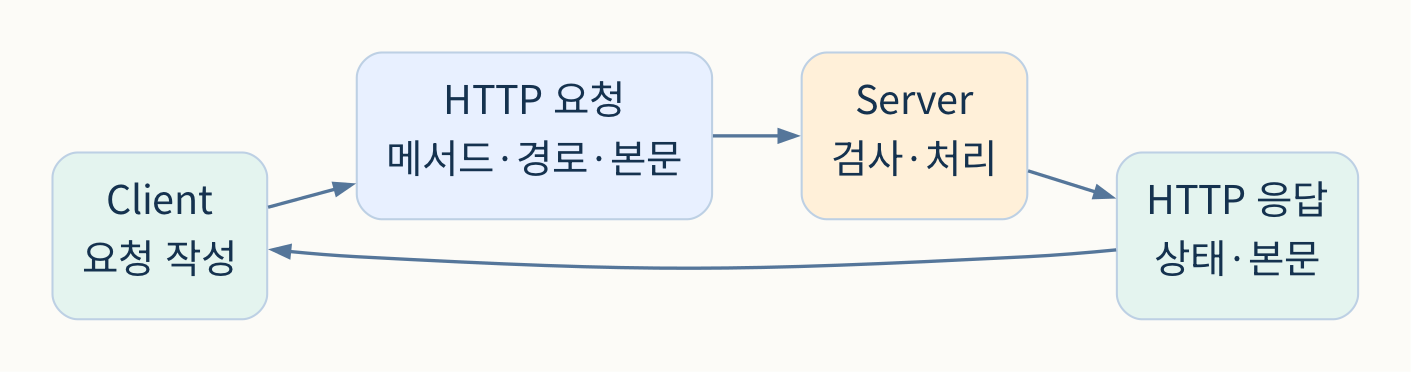

**그림 3.1.3.1 — 요청과 응답은 서로 다른 데이터입니다**

Client가 메서드·경로·본문을 정하고 Server가 상태와 본문을 반환합니다. 성공 상태를 받은 다음 응답 구조를 읽습니다.

**보면서 확인:** 404와 JSON 파싱 오류가 각각 어느 위치에서 생기는지 찾아보세요.

**표현 범위:** 이 도식은 인증·TLS·프록시를 생략한 기본 HTTP 흐름입니다.


In [ ]:
import httpx
from starlette.applications import Starlette
from starlette.responses import JSONResponse
from starlette.routing import Route
async def health(request):
    return JSONResponse({"status": "ready", "data": "training"})
web_app = Starlette(routes=[Route("/health", health)])
async with httpx.AsyncClient(transport=httpx.ASGITransport(app=web_app), base_url="http://training.local") as http:
    ok = await http.get("/health")
    missing = await http.get("/missing")
print(ok.status_code, ok.json())
print("없는 경로:", missing.status_code)


**CodeMate와 확인하기**

> /health가 성공했을 때 확인한 범위를 적어 주세요. 도구 권한과 모델 인증까지 정상이라고 말할 수 있는지 설명하고, HTTP 404와 연결 거부의 차이를 재현 방법과 함께 적어 주세요.


### 3.1.4 연결 실패를 단계별로 좁히기

오류를 만났을 때 먼저 실패한 경계를 이름 붙입니다. 프로세스가 시작하지 못했는지, 접속할 수 없는지, 경로가 없는지, 인증이 실패했는지, 응답 구조가 다른지 구분합니다. 그다음 그 경계의 작은 요청부터 다시 실행합니다.

모델에 문제가 생겼다고 모든 연결 코드를 바꾸거나, 서버가 실행됐다고 모든 기능을 확인했다고 말하면 원인을 놓칩니다. 성공 조건도 범위를 붙여 표현하세요. “Card 조회 성공”, “도구 목록 조회 성공”, “도구 실행 성공”은 서로 다릅니다.

다음 실습에서는 발견→목록→호출을 각각 실행하며 확인 범위를 늘립니다. 빠르게 끝낸 경우에는 실패 응답을 추가해 오류 안내를 개선하세요.


In [ ]:
connection_steps = ["프로세스 시작", "주소 연결", "기능 발견", "입력 검사", "실행", "응답 해석"]
for position, step in enumerate(connection_steps):
    print(step, "→ 다음 확인:", connection_steps[position + 1] if position + 1 < len(connection_steps) else "결과의 의미")


**CodeMate와 확인하기**

> “도구 목록은 보이지만 호출이 실패한다”는 상황의 원인 후보를 입력·권한·서버 처리로 나눠 주세요. 각 후보를 확인할 최소 요청을 적고, 확인되지 않은 원인을 확정하지 마세요.


## 3.2 MCP로 도구 연결하기

**이 블록의 결과물:** Tools·Resources·Prompts를 제공하고, 실제 MCP Client와 LangChain 어댑터로 호출합니다.


### 3.2.1 Host·Client·Server의 책임

MCP는 애플리케이션과 외부 도구·자료를 연결하는 프로토콜입니다. Host는 사용자가 이용하는 애플리케이션이며 모델과 실행 정책을 관리합니다. Client는 서버와 통신하고, Server는 도구·자료·프롬프트를 제공합니다.

도구를 MCP로 제공해도 도구의 효과와 권한을 검토할 책임이 사라지지 않습니다. 이름과 스키마를 발견한 뒤 어떤 상황에서 사용할지 Host가 결정해야 합니다. MCP 자체가 모델의 답변 품질이나 모든 도구의 안전성을 보장하지 않습니다.

통합본에서는 교육용 문서 검색을 MCP로 제공합니다. 원본 PDF의 SSE 예제와 달리 새 서버는 stdio 또는 Streamable HTTP 경로를 사용합니다. 연결 방식은 서버와 클라이언트가 일치해야 합니다.


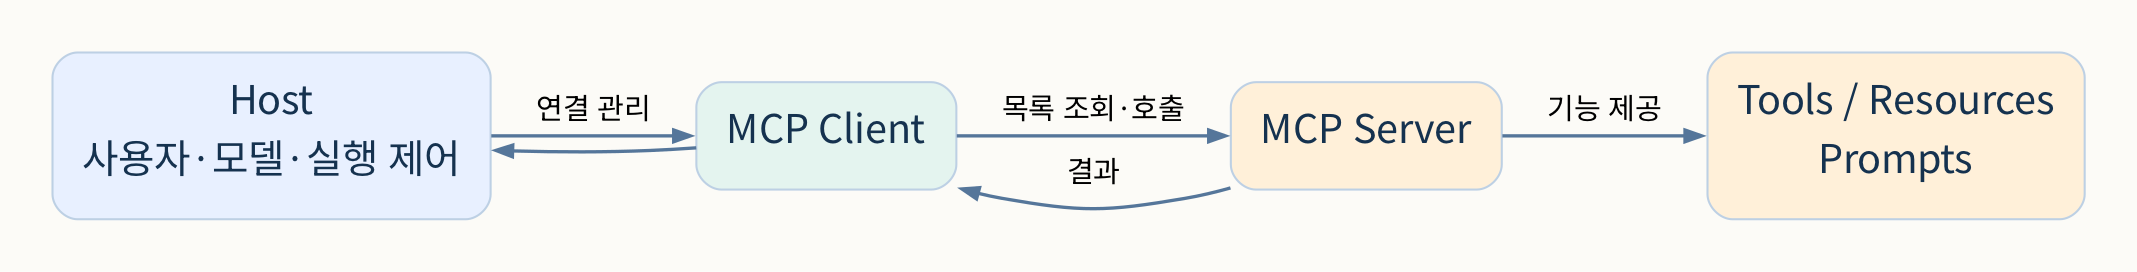

**그림 3.2.1.1 — Host 안의 Client가 Server와 통신합니다**

Host는 사용자 요청과 실행 정책을 관리하고, Server는 검색 기능과 자료를 제공합니다. Client는 양쪽의 연결 계층입니다.

**보면서 확인:** 도구 권한을 검토하는 책임이 프로토콜 도입 뒤에도 필요한 이유를 말해 보세요.

**표현 범위:** 실제 인증 방식과 전송 세부는 이 역할도에 포함하지 않았습니다.


In [ ]:
from fastmcp import Client
from courseware.mcp_server import build_mcp
mcp_server = build_mcp()
async with Client(mcp_server) as mcp_client:
    available_tools = await mcp_client.list_tools()
print([(tool.name, tool.description) for tool in available_tools])


**실행에서 볼 것**

모델 없이 도구 목록을 가져왔습니다. MCP 연결에 항상 LLM 호출이 필요한 것은 아닙니다.


**CodeMate와 확인하기**

> 이 셀에서 Host·Client·Server를 각각 찾아 주세요. search_knowledge를 다른 앱에서도 쓰게 할 때 어떤 코드가 그대로 유지되고 어떤 연결 설정이 바뀌는지 설명해 주세요.


### 3.2.2 Tools·Resources·Prompts 실행하기

Tool은 호출 가능한 기능입니다. Resource는 URI로 읽을 수 있는 자료입니다. Prompt는 반복해서 사용하는 메시지 작성 틀입니다. 셋을 모두 함수처럼 같은 방법으로 호출하지 않고 각각의 인터페이스를 사용합니다.

검색 도구에는 질문과 후보 수를 넘깁니다. 서버 공지 Resource에서는 자료의 성격을 읽고, Prompt에서는 근거 중심 답변 지시를 가져옵니다. 도구 응답의 텍스트와 구조화된 데이터 중 무엇을 다음 단계에 전달할지도 확인하세요.

아래 Client는 같은 프로세스의 서버와 연결합니다. 프로토콜 기능을 연습하기 위한 방식이며, 다음 셀에서는 실제 하위 프로세스를 띄우는 stdio로 바꿉니다.


In [ ]:
async with Client(mcp_server) as mcp_client:
    tool_result = await mcp_client.call_tool("search_knowledge", {"query": "MCP 도구", "k": 2})
    resource_result = await mcp_client.read_resource("course://notice")
    prompt_result = await mcp_client.get_prompt("evidence_answer", {"question": "MCP란 무엇인가요?"})
print("검색 문서:", [doc["id"] for doc in tool_result.data])
print("Resource:", resource_result[0].text)
print("Prompt:", prompt_result.messages[0].content.text)


**CodeMate와 확인하기**

> 서버에 교육용 문서 ID 하나를 입력받아 본문을 반환하는 읽기 전용 Tool을 추가해 주세요. 존재하지 않는 ID와 빈 입력의 결과를 정하고, Tool과 Resource 중 어떤 방식이 적절한지도 설명해 주세요. 파일 전체 접근 권한은 추가하지 마세요.


### 3.2.3 stdio와 get_tools로 LangChain에 연결하기

stdio에서는 Client가 서버 프로세스를 시작하고 표준 입출력으로 통신합니다. 서버가 별도 터미널에서 이미 실행 중이어야 하는 HTTP 방식과 다릅니다. stdio 서버는 프로토콜 메시지와 일반 출력이 섞이지 않도록 관리해야 합니다.

`MultiServerMCPClient.get_tools()`는 서버의 도구를 LangChain Tool로 가져옵니다. 가져온 도구는 `ainvoke`로 호출하거나 모델의 도구 목록에 연결할 수 있습니다. 목록 조회와 실제 호출을 모두 확인하세요.

아래는 현재 커널의 Python으로 서버를 실행합니다. `PYTHONPATH`는 이 프로젝트의 src만 넘깁니다. 서버는 교육용 파일만 읽으므로 API 키가 필요하지 않습니다. 종료 시 어댑터가 연결 수명을 관리합니다.


In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient
mcp_connections = {
    "course": {
        "transport": "stdio",
        "command": sys.executable,
        "args": ["-m", "courseware.mcp_server", "--stdio"],
        "env": {"PYTHONPATH": str(ROOT / "src")},
    }
}
adapter = MultiServerMCPClient(mcp_connections)
langchain_tools = await adapter.get_tools()
search_tool = next(tool for tool in langchain_tools if tool.name == "search_knowledge")
print("LangChain Tool:", search_tool.name)
print(await search_tool.ainvoke({"query": "RAG 검색", "k": 1}))


**실행에서 볼 것**

이 셀은 실제 하위 프로세스와 MCP 통신을 사용합니다. 외부 LLM은 호출하지 않습니다. 실제 모델에 붙일 때는 create_agent의 tools에 이 목록을 전달할 수 있습니다.


**CodeMate와 확인하기**

> 서버를 Streamable HTTP로 실행하는 터미널 명령과 Client 설정을 짝으로 적어 주세요. 서버 경로 /mcp와 클라이언트 URL을 일치시키고, stdio 설정을 그대로 섞지 마세요. 연결 실패 때 어느 단계를 먼저 확인할지도 설명해 주세요.


### 3.2.4 도구 수정과 계약 검토

도구를 수정하면 함수 코드뿐 아니라 이름·설명·인자 범위·반환 형식이 달라질 수 있습니다. Client와 모델은 발견한 스키마에 의존하므로 변경 뒤 목록을 다시 읽고 실제 호출을 확인해야 합니다.

오류를 빈 성공 결과로 바꾸면 사용자는 자료가 없는 것과 요청이 잘못된 것을 구별하지 못합니다. 잘못된 k는 입력 오류, 맞는 질문인데 결과가 없으면 정상적인 빈 검색 결과로 구분합니다.

CodeMate가 도구를 추가했다면 정상 입력과 경계 입력을 같은 연결 방식에서 실행하세요. Python 함수를 직접 호출한 테스트만으로 프로토콜 연결까지 확인했다고 말하지 않습니다.


In [ ]:
from fastmcp.exceptions import ToolError
async with Client(mcp_server) as mcp_client:
    empty = await mcp_client.call_tool("search_knowledge", {"query": "휴게실 위치", "k": 2})
    print("근거 없음:", empty.data)
    try:
        await mcp_client.call_tool("search_knowledge", {"query": "RAG", "k": 99})
    except ToolError:
        print("입력 범위 오류를 MCP 호출에서 확인했습니다.")


**CodeMate와 확인하기**

> search_knowledge의 k 허용 범위를 스키마에도 드러내도록 고쳐 주세요. 정상 1·5, 오류 0·6을 MCP Client로 호출해 확인하고, Python 함수 검사와 MCP 스키마 검사의 차이를 설명해 주세요.


## 3.3 A2A로 작업 위임하기

**이 블록의 결과물:** Agent Card로 능력을 발견하고, Researcher에 요청한 결과를 출처와 함께 검토합니다.


### 3.3.1 MCP와 A2A의 책임 경계

MCP로는 도구·자료·프롬프트를 발견하고 호출합니다. A2A는 독립된 Agent가 제공하는 능력을 발견하고 작업을 요청하는 통신 규약입니다. 한 Agent가 MCP 도구를 사용하면서 다른 Agent에는 A2A로 일을 맡길 수도 있습니다.

**Agent Card**는 이름·설명·기능·접속 방법을 알리는 명세입니다. **Message**는 참여자가 주고받는 내용이고, **Task**는 진행 상태를 가진 작업입니다. **Artifact**는 작업이 만든 산출물입니다. 메시지 응답만 하는 짧은 예제에 장기 Task의 대기·취소가 구현됐다고 말하면 안 됩니다.

이 실습은 Agent Card와 JSON-RPC 요청을 실제 SDK로 처리하되 Researcher 답변은 교육용 문서를 발췌합니다. 서버의 `streaming=False`도 기능 계약의 일부입니다. 서버가 지원하지 않는 기능을 Client에서 임의로 가정하지 않습니다.


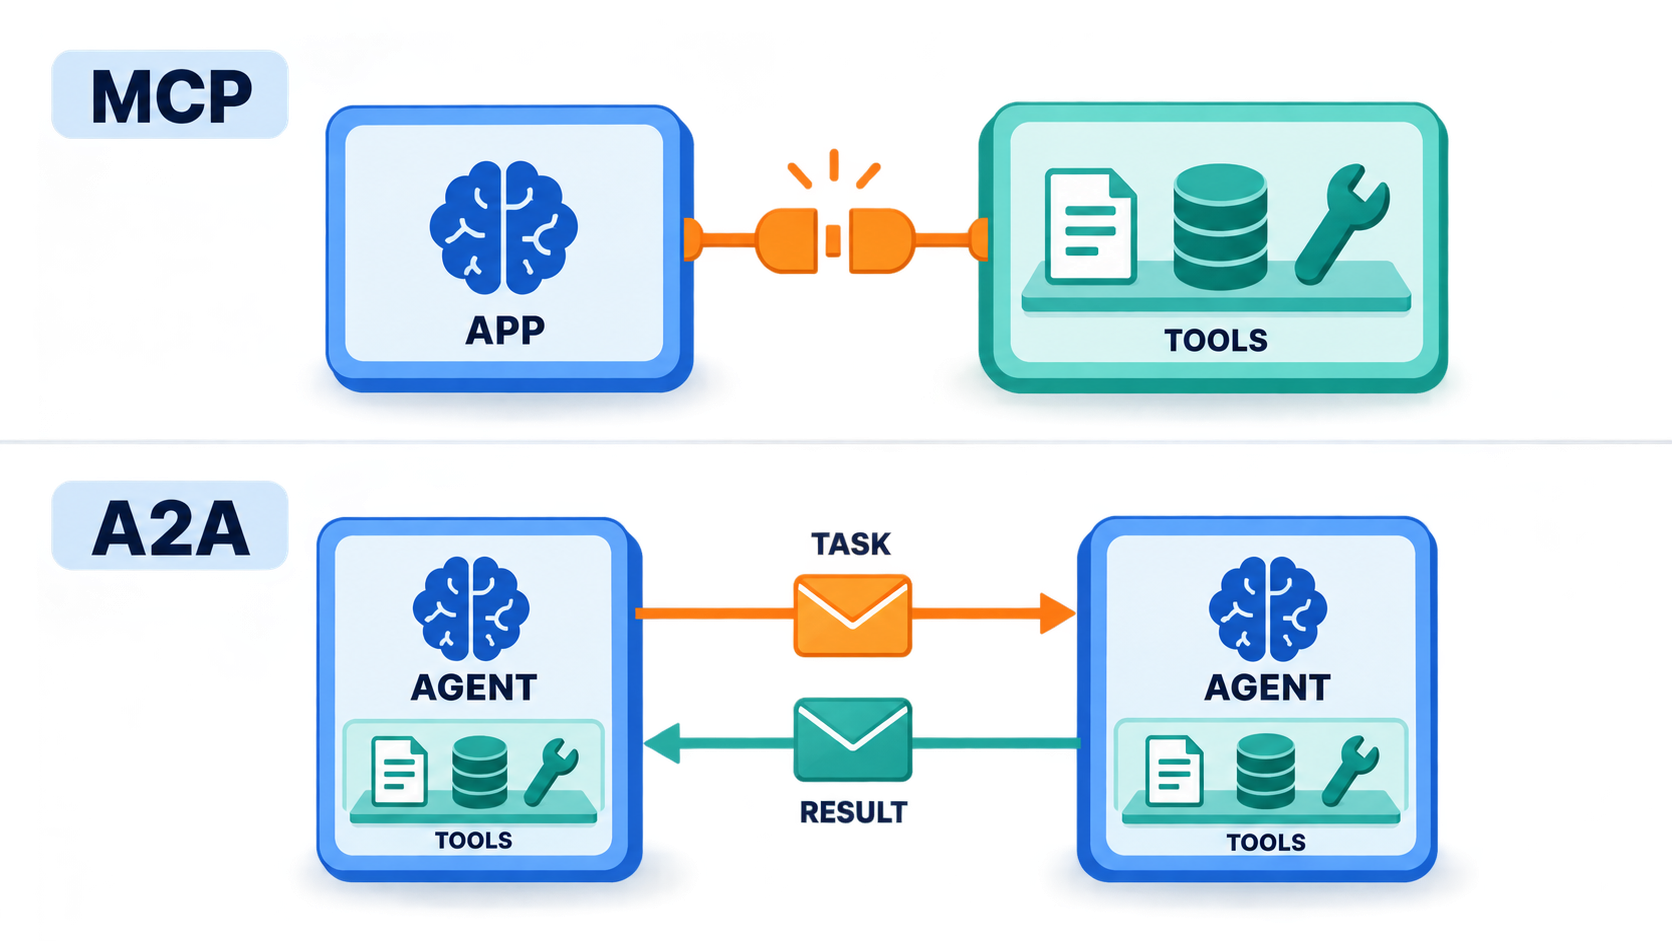

**그림 3.3.1.1 — 도구 연결과 Agent 위임**

왼쪽은 Agent가 도구를 호출하는 관계, 오른쪽은 Agent가 다른 Agent에 작업을 맡기는 관계입니다.

**보면서 확인:** 통신 상대가 기능인지 독립된 작업 수행자인지 비교하세요.

**표현 범위:** 두 규약은 함께 쓸 수 있습니다. A2A가 모델의 정확성이나 상대의 신뢰성을 보증하지는 않습니다.


In [ ]:
import a2a.types as a2a_types
example_skill = a2a_types.AgentSkill(id="research", name="교육 자료 조사", description="근거 문서를 찾아 반환", tags=["research"])
print(example_skill.name, list(example_skill.tags))


**CodeMate와 확인하기**

> 문서 검색 함수, 독립 Researcher, 긴 보고서 작성 작업을 각각 MCP Tool·A2A Message·A2A Task 관점에서 비교해 주세요. Task를 쓰는 경우 대기·완료·실패를 어떻게 보여 줄지도 적어 주세요.


### 3.3.2 Agent Card와 서버 경로 확인

A2A 서버는 발견 경로와 실행 경로를 제공합니다. Card에 적힌 URL은 실제 실행 경로와 일치해야 합니다. Card가 열려도 실행 권한·입력·모델 연결이 모두 정상이라는 뜻은 아닙니다.

아래는 `courseware.a2a_server`의 실제 Starlette 앱을 구성합니다. HTTPX ASGI 전송을 사용해 별도 포트 없이 Card를 가져옵니다. 다른 프로세스로 접속하려면 터미널에서 `uv run python -m courseware.a2a_server`를 실행하고 일반 HTTP Client를 사용합니다.

SDK 1.x 예제이므로 이전 교안의 타입 이름과 다를 수 있습니다. 잠금 파일을 기준으로 실행하고 버전을 바꿀 때는 서버·Client를 함께 확인하세요.


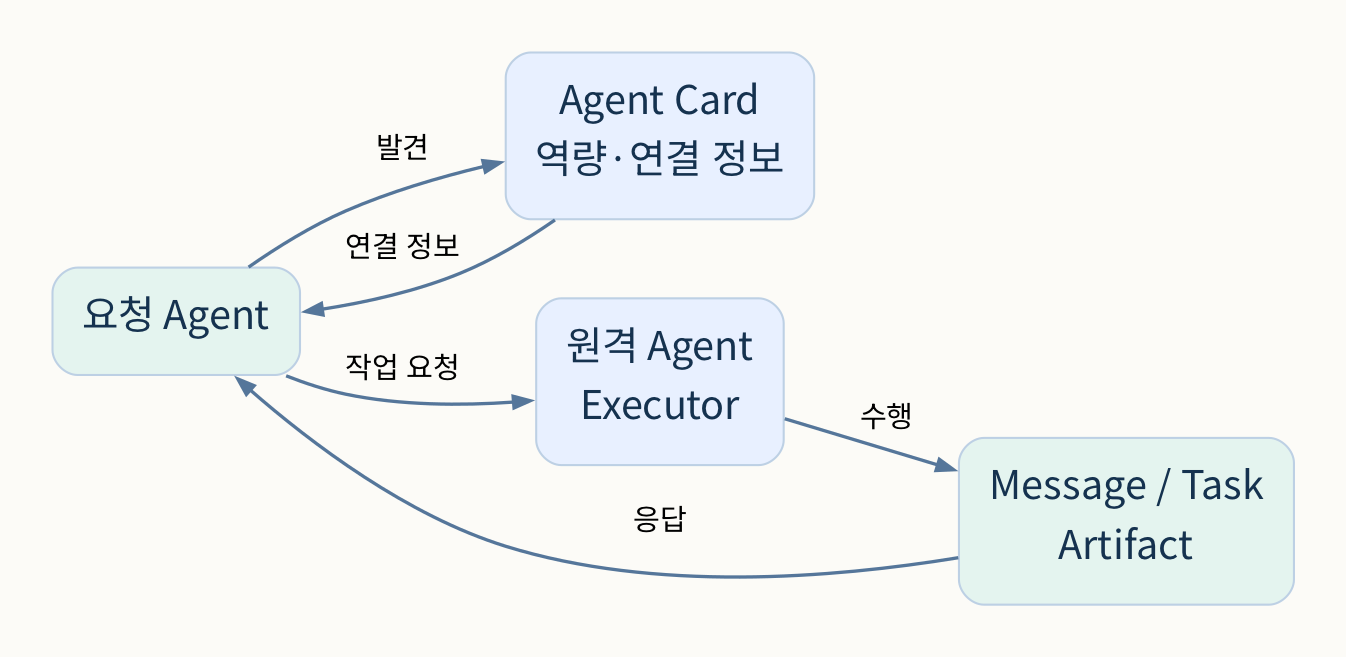

**그림 3.3.2.1 — 발견 후 요청하기**

Card에서 접속 방법과 능력을 읽은 뒤 실행 요청을 보냅니다.

**보면서 확인:** Card 조회와 작업 요청이 별개의 단계인 것을 확인하세요.

**표현 범위:** 이 도식은 단순 응답 경로입니다. 인증·장기 Task·취소는 구현별로 추가해야 합니다.


In [ ]:
from courseware.a2a_server import build_a2a_app
from a2a.client import A2ACardResolver, ClientConfig
from a2a.client.base_client import BaseClient
from a2a.client.transports.jsonrpc import JsonRpcTransport
from uuid import uuid4
A2A_URL = "http://training.local"
a2a_app = build_a2a_app(A2A_URL)
async with httpx.AsyncClient(transport=httpx.ASGITransport(app=a2a_app), base_url=A2A_URL, headers={"A2A-Version": "1.0"}) as http:
    card = await A2ACardResolver(http, A2A_URL).get_agent_card()
print(card.name)
print([(interface.protocol_binding, interface.url) for interface in card.supported_interfaces])
print("streaming:", card.capabilities.streaming)


**CodeMate와 확인하기**

> Card에 적힌 경로를 바꾸었는데 실제 서버 라우트는 그대로일 때 무엇이 실패할지 예측해 주세요. 발견 성공과 실행 성공을 각각 검증하는 테스트를 제안해 주세요.


### 3.3.3 Message를 보내고 응답 읽기

Client는 메시지의 역할·내용·식별자를 지정합니다. Server의 Executor는 입력을 받아 일을 수행하고 EventQueue에 결과를 전달합니다. Client는 응답 타입을 확인한 뒤 텍스트를 읽어야 합니다.

아래 `ask_researcher`는 실제 A2A 직렬화·라우팅·Executor를 거칩니다. 응답에는 교육용 문서 출처가 포함됩니다. 이 예제에서는 Message가 돌아오지만, 다른 서버에서 Task가 돌아오면 상태를 추적하는 처리가 추가로 필요합니다.

메시지 ID는 요청을 구별하는 값입니다. 같은 주제를 다시 보낸 것인지, 같은 요청을 재시도한 것인지 구분하지 않으면 중복 작업을 만들 수 있습니다. 식별자만 붙인다고 자동으로 중복이 방지되지는 않습니다.


In [ ]:
async def ask_researcher(question):
    async with httpx.AsyncClient(transport=httpx.ASGITransport(app=a2a_app), base_url=A2A_URL, headers={"A2A-Version": "1.0"}) as http:
        remote_card = await A2ACardResolver(http, A2A_URL).get_agent_card()
        transport = JsonRpcTransport(http, remote_card, A2A_URL + "/")
        client = BaseClient(remote_card, ClientConfig(streaming=False), transport, [])
        message = a2a_types.Message(role=a2a_types.Role.ROLE_USER, message_id=str(uuid4()), parts=[a2a_types.Part(text=question)])
        answers = []
        async for event in client.send_message(a2a_types.SendMessageRequest(message=message)):
            if event.HasField("message"):
                answers.extend(part.text for part in event.message.parts if part.HasField("text"))
            else:
                raise TypeError("이 예제는 즉시 Message 응답만 지원합니다.")
        return "\n".join(answers)
remote_answer = await ask_researcher("RAG 검색 근거")
print(remote_answer)
assert "[D1]" in remote_answer


**실행에서 볼 것**

Card와 응답 본문을 각각 확인하세요. SDK 1.1.5는 즉시 응답 정리 과정에서 Dispatcher 경고를 출력할 수 있습니다. 응답 검증과 별도로 구분하며, 오류를 성공 응답으로 바꾸지 않습니다.


**CodeMate와 확인하기**

> Message의 텍스트를 바로 최종 보고서로 내보내지 않고, 출처와 응답 타입을 확인하는 검토 단계를 추가해 주세요. 오류·빈 결과·정상 결과를 서로 다른 상태로 처리해 주세요.


### 3.3.4 Researcher에 맡길 범위를 정하기

위임 지시에는 목적, 조사 범위, 반환 형식, 제외할 내용을 적습니다. “잘 조사해 줘”보다 “주어진 자료에서 승인 시점과 거절 경로를 찾아 출처와 함께 반환”이 검토하기 쉽습니다.

요청을 다른 Agent에 맡겨도 최종 책임은 사라지지 않습니다. Supervisor는 근거가 있는지, 요구한 형식을 지켰는지, 다음 단계로 넘겨도 되는지 판단합니다. 외부 자료의 문장은 실행 지시가 아니라 검토할 데이터로 취급합니다.

여기서는 알려진 주제와 없는 주제를 둘 다 요청합니다. 자료가 없는 경우를 성공적인 거절로 다루는 기준을 만들어 두면, 그럴듯한 답변을 만들어내는 오류를 찾기 쉽습니다.


In [ ]:
for question in ["승인 거절", "구내식당 오늘 메뉴"]:
    response = await ask_researcher(question)
    print(question, "→", response)


**CodeMate와 확인하기**

> Researcher에게 전달할 지시문과 Supervisor의 합격 기준을 각각 작성해 주세요. 근거 없음이면 Writer를 실행하지 않도록 하고, 실제로 없는 주제를 넣어 확인해 주세요.


## 3.4 LangGraph의 상태·메모리·병렬 실행

**이 블록의 결과물:** 서브그래프의 경계를 정의하고 세션 상태와 공유 저장소를 구분하며 여러 Worker 결과를 합칩니다.


### 3.4.1 Subgraph의 입출력 경계

Subgraph는 관련 노드를 하나의 작업 단위로 묶은 그래프입니다. 상위 그래프에서 단계를 쉽게 읽을 수 있고, 같은 작업을 따로 검증할 수 있습니다. 다만 작은 함수 하나를 무조건 그래프로 감싸면 구조만 늘어납니다.

상위 State와 하위 State가 같으면 직접 연결할 수 있습니다. 다를 때는 어댑터 함수가 필요한 입력을 넘기고 결과를 상위 키로 변환합니다. 아래에서는 상위의 `topic`을 하위의 `query`로 바꿉니다.

하위 그래프가 가진 임시 키를 모두 상위로 흘려보내지 않습니다. 경계를 좁히면 다른 팀이 Worker 내부를 수정해도 상위 흐름이 받는 영향이 작아집니다.


In [ ]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
import operator
class ChildState(TypedDict):
    query: str
    evidence: list[dict]
child_builder = StateGraph(ChildState)
child_builder.add_node("search", lambda s: {"evidence": retrieve(s["query"], 2)})
child_builder.add_edge(START, "search")
child_builder.add_edge("search", END)
research_subgraph = child_builder.compile()
class ParentState(TypedDict):
    topic: str
    sources: list[str]
def call_research(state):
    child_result = research_subgraph.invoke({"query": state["topic"]})
    return {"sources": [d["id"] for d in child_result["evidence"]]}
parent_builder = StateGraph(ParentState)
parent_builder.add_node("research", call_research)
parent_builder.add_edge(START, "research")
parent_builder.add_edge("research", END)
print(parent_builder.compile().invoke({"topic": "RAG 검색"}))


**CodeMate와 확인하기**

> 하위 그래프에 내부 디버그 필드를 추가해도 상위 출력에는 노출되지 않게 해 주세요. 입력 변환·출력 변환을 각각 표시하고 두 그래프를 독립적으로 검증해 주세요.


### 3.4.2 Checkpointer와 Store

Checkpointer는 thread별 그래프 실행 상태를 저장합니다. 중단된 실행을 재개하거나 같은 대화를 이어갈 때 사용합니다. Store는 여러 실행에서 조회할 데이터를 namespace와 key로 저장하는 인터페이스입니다.

`thread_id`가 같으면 같은 실행 맥락을 참조합니다. 사용자 ID와 thread ID는 서로 다른 개념입니다. 한 사용자가 여러 대화를 만들 수도 있고, 잘못된 사용자 namespace를 쓰면 다른 사용자의 정보가 섞일 수도 있습니다.

아래는 InMemorySaver와 InMemoryStore를 **둘 다 compile에 연결**합니다. 메모리 구현이므로 커널이 끝나면 사라집니다. Store를 사용했다고 디스크 영속성이 생기거나 Checkpoint가 자동으로 Store로 복사되는 것은 아닙니다.


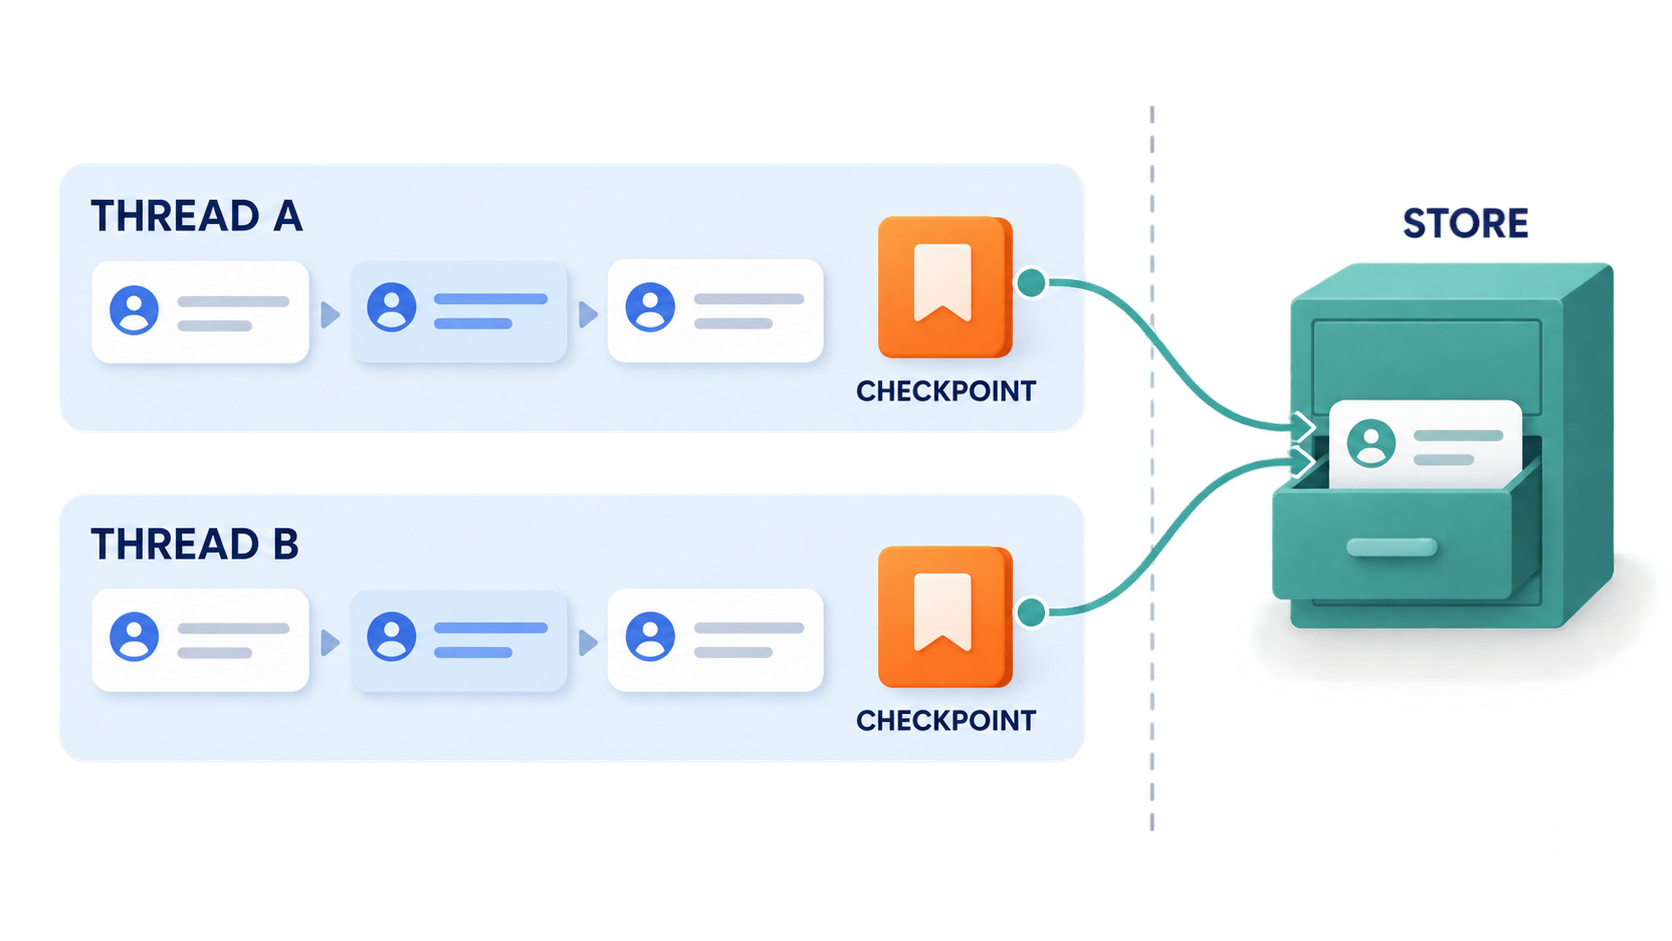

**그림 3.4.2.1 — 대화 상태와 사용자 데이터**

같은 대화를 이어가는 상태와 여러 대화에서 참고할 정보를 분리해서 관리합니다.

**보면서 확인:** thread가 달라져도 사용자 선호를 별도로 조회할 수 있다는 점을 보세요.

**표현 범위:** 그림의 관계는 저장 범위를 뜻합니다. Checkpoint에서 Store로 자동 복사되지 않으며 메모리 구현은 재시작 후 유지되지 않습니다.


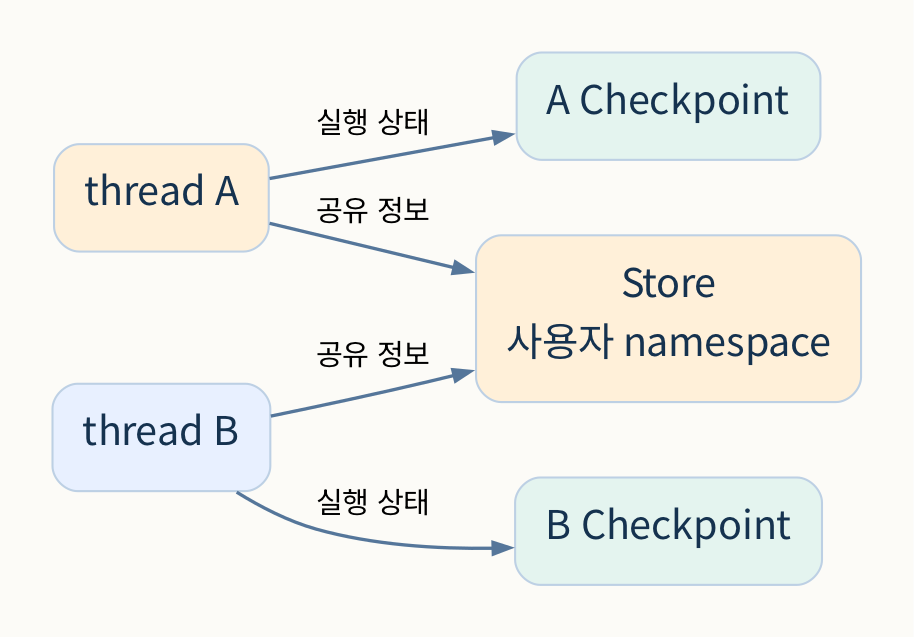

**그림 3.4.2.2 — 저장 범위를 코드로 연결하기**

Checkpointer와 Store를 그래프에 각각 주입합니다.

**보면서 확인:** compile에 두 객체가 연결됐는지 위 코드에서 확인하세요.

**표현 범위:** 이 예제는 영속 DB와 인증을 구현하지 않습니다.


In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.runtime import Runtime
class MemoryState(TypedDict):
    visits: int
    preference: str
class UserContext(TypedDict):
    user_id: str
shared_store = InMemoryStore()
shared_store.put(("learner-a", "preferences"), "style", {"language": "한국어"})
def recall(state: MemoryState, runtime: Runtime[UserContext]):
    item = runtime.store.get((runtime.context["user_id"], "preferences"), "style")
    return {"visits": state.get("visits", 0) + 1, "preference": item.value["language"] if item else "기본값"}
memory_builder = StateGraph(MemoryState, context_schema=UserContext)
memory_builder.add_node("recall", recall)
memory_builder.add_edge(START, "recall")
memory_builder.add_edge("recall", END)
memory_graph = memory_builder.compile(checkpointer=InMemorySaver(), store=shared_store)
thread_a = {"configurable": {"thread_id": "conversation-a"}}
print(memory_graph.invoke({"visits": 0}, thread_a, context={"user_id": "learner-a"}))
print(memory_graph.invoke({}, thread_a, context={"user_id": "learner-a"}))
print(memory_graph.invoke({"visits": 0}, {"configurable": {"thread_id": "conversation-b"}}, context={"user_id": "learner-b"}))
assert memory_graph.get_state(thread_a).values["visits"] == 2


**CodeMate와 확인하기**

> 같은 사용자·다른 thread와 다른 사용자·다른 thread를 비교하는 실행을 추가해 주세요. 공유할 선호와 분리할 대화 이력을 설명하고, namespace만으로 인증이 완성되지 않는 이유를 적어 주세요.


### 3.4.3 Send로 여러 Worker에 배분하기

Fan-out은 일을 여러 갈래로 나누고, Fan-in은 결과를 모으는 과정입니다. LangGraph의 Send는 실행할 노드와 그 노드에 줄 상태를 지정합니다. 주제 수에 따라 Worker 수가 달라지는 경우에 사용할 수 있습니다.

여러 Worker가 같은 결과 키를 갱신하면 합치는 규칙이 필요합니다. 이 예제는 리스트를 더하는 Reducer를 사용하고 결과를 출력할 때 문서 ID로 정렬합니다. 완료 순서를 그대로 의미 있는 순서라고 가정하지 않습니다.

병렬화는 독립 작업에 적용합니다. 앞 단계의 결과가 필요한 일을 동시에 시작하면 아직 없는 정보를 읽게 됩니다. 속도 비교는 실제 측정이 필요하며, Worker 수만으로 빨라졌다고 단정하지 않습니다.


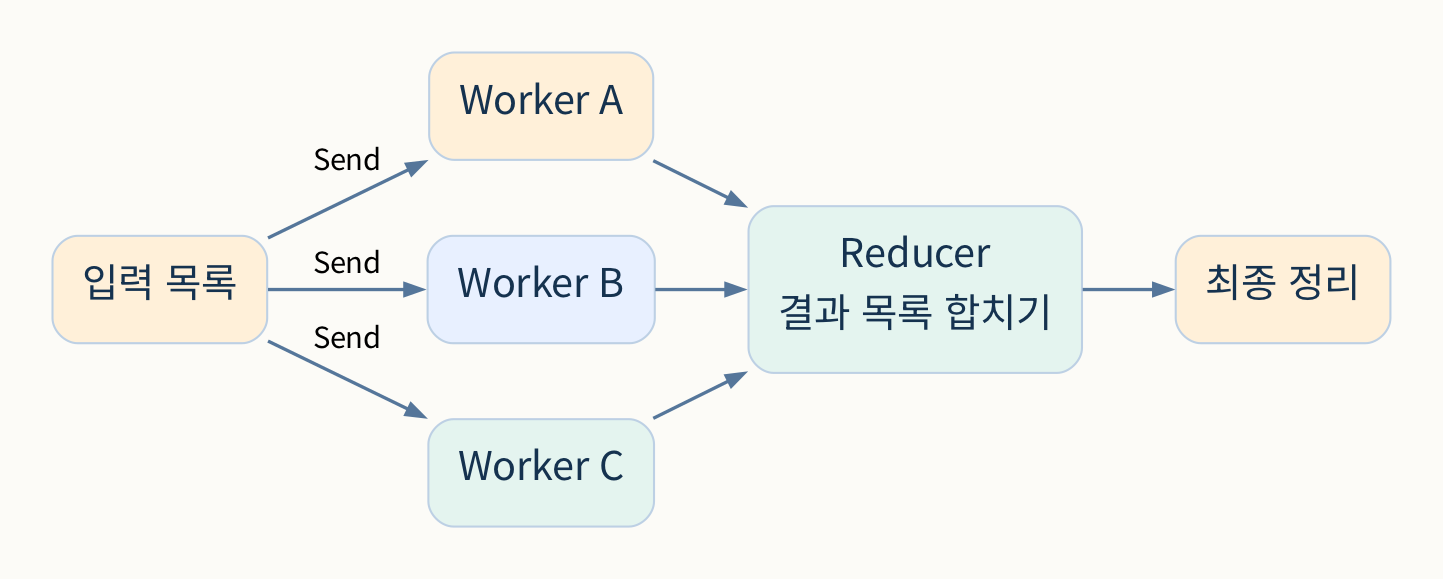

**그림 3.4.3.1 — 나누기와 합치기는 한 쌍입니다**

각 Worker가 독립된 입력을 처리하고 Reducer가 결과를 합칩니다.

**보면서 확인:** 각 Worker가 전체 State 대신 필요한 입력만 받는지 보세요.

**표현 범위:** 동시 실행이 항상 빠르다는 뜻은 아닙니다. 외부 API 제한과 실제 비용은 별도로 측정합니다.


In [ ]:
from langgraph.types import Send
class ParallelState(TypedDict):
    topics: list[str]
    findings: Annotated[list[dict], operator.add]
class WorkerState(TypedDict):
    topic: str
def distribute(state):
    return [Send("worker", {"topic": topic}) for topic in state["topics"]]
def worker(state: WorkerState):
    return {"findings": [{"topic": state["topic"], "ids": [d["id"] for d in retrieve(state["topic"], 1)]}]}
parallel_builder = StateGraph(ParallelState)
parallel_builder.add_node("worker", worker)
parallel_builder.add_conditional_edges(START, distribute)
parallel_builder.add_edge("worker", END)
parallel_graph = parallel_builder.compile()
parallel_result = parallel_graph.invoke({"topics": ["RAG", "승인", "MCP"], "findings": []})
print(sorted(parallel_result["findings"], key=lambda row: row["topic"]))
assert len(parallel_result["findings"]) == 3


**CodeMate와 확인하기**

> Worker가 같은 키를 동시에 수정할 때 Reducer가 왜 필요한지 설명해 주세요. 결과 표시 순서를 정하고, Worker 하나의 결과 없음도 다른 결과와 구분해 표시해 주세요.


### 3.4.4 반복 실행·중복·실패를 다루기

한 번 실행한 결과만 보고 병렬 처리가 끝났다고 판단하지 않습니다. 입력이 비었을 때, 같은 주제가 반복될 때, 한 Worker가 실패할 때를 함께 확인합니다. 중복 입력을 허용할지 합칠지는 요구사항에 따라 정합니다.

아래 실행기는 입력에서 중복을 제거하고 빈 목록은 즉시 반환합니다. 같은 그래프를 다시 실행할 때 새 `findings=[]`를 전달하므로 이전 결과가 섞이지 않습니다. Checkpointer를 추가한 경우에는 같은 thread의 기존 상태와 Reducer가 어떻게 합쳐지는지 다시 살펴야 합니다.

Worker 실패를 빈 결과로 감추지 않습니다. 부분 성공을 허용하려면 결과에 `status`와 `error`를 담는 별도 계약을 먼저 설계하고, 사용자가 실패한 주제를 볼 수 있어야 합니다.


In [ ]:
def run_topics(topics):
    unique = list(dict.fromkeys(topic.strip() for topic in topics if topic.strip()))
    if not unique:
        return []
    result = parallel_graph.invoke({"topics": unique, "findings": []})
    return sorted(result["findings"], key=lambda row: row["topic"])
assert run_topics([]) == []
assert len(run_topics(["RAG", "RAG"])) == 1
assert run_topics(["RAG", "MCP"]) == run_topics(["MCP", "RAG"])
print(run_topics(["RAG", "없는주제"]))


**CodeMate와 확인하기**

> 일부 Worker가 실패한 경우 status·error를 포함하는 결과 계약을 설계하고 구현해 주세요. 전체 중단과 부분 성공 중 선택 이유를 밝히고, 빈 입력·중복 입력·실패 입력을 재실행해 주세요.


### 3.4.5 경계별 검토로 정리하기

오늘 늘어난 경계는 프로세스, Agent, 그래프, 저장 범위, 병렬 Worker입니다. 각 경계에서 입력·출력·실패·재시도 조건을 적으면 복잡한 코드를 나누어 읽을 수 있습니다.

MCP와 A2A는 모델을 더 똑똑하게 만드는 설정이 아니라 연결 계약입니다. Subgraph와 Reducer도 정답을 만드는 장치가 아니라 실행 구조를 관리하는 도구입니다. 결과의 의미는 문서와 요구사항에 비추어 검토해야 합니다.

다음 일차에서는 이 연결들을 목표·제약·평가로 감싸 반복 가능한 작업 환경을 만듭니다. CodeMate에 변경을 요청할 때도 같은 경계를 사용해 수정 범위를 작게 잡으세요.


In [ ]:
review = {
    "MCP": "도구 발견·입력·실행 결과",
    "A2A": "Card·Message·지원 기능",
    "Subgraph": "입력 변환·출력 변환",
    "Memory": "thread·사용자 namespace·영속성",
    "Parallel": "분배·Reducer·중복·실패",
}
for boundary, checks in review.items():
    print(boundary, "→", checks)


**CodeMate와 확인하기**

> 오늘 수정한 코드 하나를 고르고 입력·출력·실패·저장 범위를 네 문장으로 설명해 주세요. 실제로 실행한 검증과 아직 실행하지 않은 검증을 구분해 제출해 주세요.


## 원본과 다음 단계

원본 교안은 [자료 대응표](../docs/LESSON_SOURCES.md)의 3일차에서 찾습니다. 실행 구현은 [MCP 서버](../src/courseware/mcp_server.py), [A2A 서버](../src/courseware/a2a_server.py)를 참고하세요. 다음은 [4일차](day04.ipynb)입니다.
